In [1]:
import json
import random
import socket
import pickle
import time  
import numpy as np
import matplotlib.pyplot as plt

class QLearningAgent:
    def __init__(self, num_actions=6, lr=0.1, gamma=0.95, epsilon=1.0, total_episodes=6500, min_epsilon=0.02):
        self.num_actions = num_actions
        self.lr = lr
        self.gamma = gamma
        self.epsilon = epsilon
        self.min_epsilon = min_epsilon
        self.epsilon_decay = min_epsilon ** (1 / total_episodes) 
        self.q_table = {}

    def state_to_key(self, state_dict):
        return (
            state_dict["px"], 
            state_dict["py"], 
            state_dict["floor"], 
            state_dict["enemy"], 
            state_dict["apple_dir"],
            state_dict.get("apple_count", 0) 
        )

    def get_q_values(self, state_key):
        if state_key not in self.q_table:
            self.q_table[state_key] = np.zeros(self.num_actions)
        return self.q_table[state_key]

    def choose_action(self, state_key, training=True):
        if training and random.random() < self.epsilon:
            return random.randint(0, self.num_actions - 1)
        q_vals = self.get_q_values(state_key)
        return int(np.argmax(q_vals))

    def update(self, state_key, action, reward, next_state_key, done):
        current_q = self.get_q_values(state_key)[action]
        max_next_q = np.max(self.get_q_values(next_state_key)) if not done else 0.0
        new_q = current_q + self.lr * (reward + (self.gamma * max_next_q) - current_q)
        self.q_table[state_key][action] = new_q

    def decay_epsilon(self):
        self.epsilon *= self.epsilon_decay
        if self.epsilon < self.min_epsilon:
            self.epsilon = self.min_epsilon

In [2]:
def run_server(total_episodes=6000):
    start_time = time.time()  
    agent = QLearningAgent(total_episodes=total_episodes)
    
    server_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    server_socket.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)
    server_socket.bind(("127.0.0.1", 9999))
    server_socket.listen(1)
    print("==================================================")
    print("[Python] Q-Learning Server running on port 9999.")
    print(f"[Python] Training for {total_episodes} episodes...")
    print("==================================================")

    client_socket, addr = server_socket.accept()
    print(f"[Python] Godot connected from {addr}")

    rewards_history = []
    apples_history = []
    distance_history = []        
    
    episode = 0
    current_episode_reward = 0.0
    prev_state_key = None
    prev_action = None
    buffer = ""

    while episode < total_episodes:
        data = client_socket.recv(4096).decode("utf-8")
        if not data:
            break
            
        buffer += data
        while "\n" in buffer:
            line, buffer = buffer.split("\n", 1)
            if not line.strip():
                continue
                
            payload = json.loads(line)
            state_key = agent.state_to_key(payload["state"])
            reward = payload["reward"]
            done = payload["done"]
            apples = payload.get("apples", 0)
            distance = payload.get("distance", 0.0)

            current_episode_reward += reward

            if prev_state_key is not None and prev_action is not None:
                agent.update(prev_state_key, prev_action, reward, state_key, done)

            if done:
                episode += 1
                agent.decay_epsilon()
                rewards_history.append(current_episode_reward)
                apples_history.append(apples)
                distance_history.append(distance)            

                print(f"Episode {episode:04d}/{total_episodes} | Total Reward: {current_episode_reward:7.2f} | Apples: {apples} | Epsilon: {agent.epsilon:.3f} | Dist: {distance:6.1f}px")
                
                current_episode_reward = 0.0
                prev_state_key = None
                prev_action = None
                action = agent.choose_action(state_key)
            else:
                action = agent.choose_action(state_key)
                prev_state_key = state_key
                prev_action = action

            response = json.dumps({"action": action}) + "\n"
            client_socket.sendall(response.encode("utf-8"))

    client_socket.close()
    server_socket.close()
    
    elapsed_seconds = time.time() - start_time
    minutes = int(elapsed_seconds // 60)
    seconds = int(elapsed_seconds % 60)
    print("\n==================================================")
    print(f"[Python] Training Completed in: {minutes}m {seconds}s")
    print(f"[Python] Average Distance: {np.mean(distance_history):.2f}px")
    print("==================================================\n")

    with open("scene4_qtable.pkl", "wb") as f:
        pickle.dump(agent.q_table, f)
    print("Q-table saved to scene4_qtable.pkl!")
    
    plot_results(rewards_history, apples_history)


def summarize_success(apples_history, window=200):
    apples = np.array(apples_history)
    n = len(apples)
    
    def rate(start, end):
        chunk = apples[start:end]
        return 100.0 * np.sum(chunk >= 2) / len(chunk) if len(chunk) else 0.0

    print("\n=== Success Rate (2/2 Apples Collected) ===")
    print(f"First {window} episodes : {rate(0, window):.1f}%")
    print(f"Last {window} episodes  : {rate(n - window, n):.1f}%")
    print(f"Overall ({n} episodes)  : {rate(0, n):.1f}%\n")
    
    roll = [100.0 * np.mean(apples[max(0, i - window):i + 1] >= 2) for i in range(n)]
    return roll


def plot_results(rewards_history, apples_history, filename="q_learning_scene4_results.png"):
    roll_success = summarize_success(apples_history, window=200)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(rewards_history, label="Episode Reward", alpha=0.5)
    if len(rewards_history) >= 10:
        moving_avg = np.convolve(rewards_history, np.ones(10)/10, mode='valid')
        ax1.plot(range(9, len(rewards_history)), moving_avg, color='red', label="Moving Avg (10)")
    ax1.set_title("Q-Learning: Total Reward per Episode (Scene 4)")
    ax1.set_xlabel("Episode")
    ax1.set_ylabel("Total Reward")
    ax1.grid(True)
    ax1.legend()

    ax2.plot(roll_success, color='green', linewidth=2, label="Success Rate (2 Apples)")
    ax2.set_title("Rolling Success Rate (Window = 200 Episodes)")
    ax2.set_xlabel("Episode")
    ax2.set_ylabel("Success Rate (%)")
    ax2.set_ylim(-5, 105)
    ax2.grid(True)
    ax2.legend()

    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

=== Final Training Summary (6,000 Episodes) ===
Total training time: 331 min 1 s (~5 h 31 min)
Success rate (2/2 apples) — first 200 episodes : 0.0%
Success rate (2/2 apples) — last 200 episodes  : 94.0%
Success rate (2/2 apples) — overall             : 18.1%
Average distance travelled per episode          : 12,051.77 px



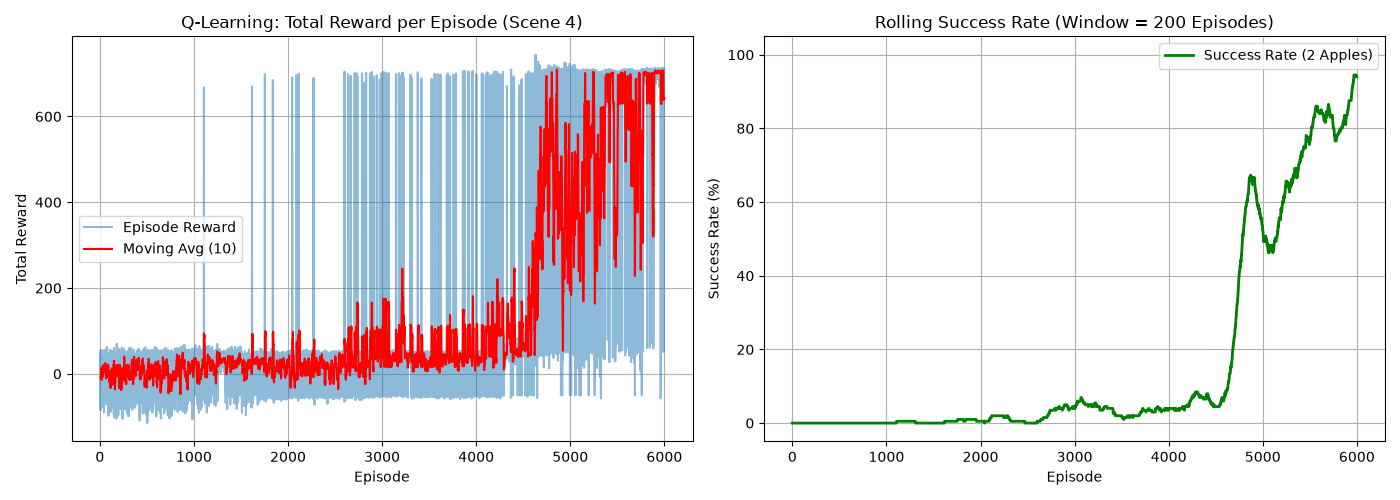

In [3]:
from IPython.display import Image, display

print("=== Final Training Summary (6,000 Episodes) ===")
print("Total training time: 331 min 1 s (~5 h 31 min)")
print("Success rate (2/2 apples) — first 200 episodes : 0.0%")
print("Success rate (2/2 apples) — last 200 episodes  : 94.0%")
print("Success rate (2/2 apples) — overall             : 18.1%")
print("Average distance travelled per episode          : 12,051.77 px\n")

display(Image(filename="q_learning_scene4_results.png"))

In [4]:
import pickle

print("=== Trained Q-Table Sample ===")
with open("scene4_qtable.pkl", "rb") as f:
    trained_q_table = pickle.load(f)

print(f"Total Unique States Learned: {len(trained_q_table)}\n")

# Print the first 5 states to prove the Q-table is populated
for i, (state, q_values) in enumerate(trained_q_table.items()):
    if i >= 5: 
        break
    # State format: (px, py, floor, enemy, apple_dir, apple_count)
    print(f"State {state} \nQ-Values: {q_values}\n")

=== Trained Q-Table Sample ===
Total Unique States Learned: 1515

State (45, 13, 1, 0, 0, 0) 
Q-Values: [6.34819582 6.90390381 6.76202733 7.06104026 8.50656098 7.22016195]

State (45, 12, 0, 0, 0, 0) 
Q-Values: [-0.81237928 -0.45680666  0.60627809  8.51106481  0.31011659  1.2021785 ]

State (45, 11, 0, 0, 0, 0) 
Q-Values: [1.71462054 9.4166892  2.23379712 3.37279961 1.0370659  1.96048405]

State (45, 10, 0, 0, 0, 0) 
Q-Values: [2.85252447 0.57069383 0.24167592 1.39997567 3.52273893 6.61388177]

State (45, 9, 0, 0, 0, 0) 
Q-Values: [5.64472494 7.08582443 6.86965032 6.00082886 8.48364233 6.09709701]

